# Mean and Median Imputation

Mean and median imputation are foundational techniques for replacing missing numerical values in a dataset. They replace all missing occurrences in a variable with either the **mean** (average) or **median** (50th percentile) calculated from the observed values.

---

## Learning Objectives
By the end of this notebook, you will be able to:
1. Understand when to choose **mean** vs. **median** based on distribution shape and skewness.
2. Prevent **data leakage** by computing imputation statistics strictly on the training set.
3. Implement mean and median imputation using both **pandas** and **scikit-learn's `SimpleImputer`**.
4. Analyze the effects of mean/median imputation on feature variance, distribution shape, and relationships between variables.

---
## 1. When to Use Mean vs. Median Imputation

| Technique | Best Suited For | Sensitivity to Outliers | Effect on Distribution |
| :--- | :--- | :--- | :--- |
| **Mean Imputation** | Normally distributed (symmetric) features without extreme outliers | High (pulled by extreme values) | Concentrates density at the mean; reduces variance |
| **Median Imputation** | Skewed features or data with outliers | Low (robust to extremes) | Concentrates density at the median; reduces variance |

### Important Assumptions and Trade-offs:
- **Assumption**: Data is Missing Completely at Random (MCAR). If missingness is informative, substituting the central tendency can introduce systematic bias.
- **Rule of Thumb**: Suitable when missingness is relatively small (< 5-10%). If missingness is high, filling many rows with a single number creates an artificial spike that distorts the distribution and underestimates standard errors.

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer

# Matplotlib configuration for clear inline plots
plt.rcParams['figure.figsize'] = (10, 4)
plt.rcParams['font.size'] = 10

---
## 2. Loading the Dataset & Preventing Data Leakage

We use the Ames House Prices dataset. To prevent **data leakage**, we must split our data into training and test sets **before** calculating the mean or median. 

> **Why?** If we compute the mean or median across the entire dataset, information from the test set leaks into our preprocessing step, creating over-optimistic evaluation results.

In [2]:
# Selected numerical features (including ones with missing values)
cols_to_use = [
    "OverallQual",  # Rates overall material and finish (no missing)
    "TotalBsmtSF",  # Total square feet of basement (no missing)
    "1stFlrSF",     # First floor square feet (no missing)
    "GrLivArea",    # Above ground living area (no missing)
    "LotFrontage",  # Linear feet of street connected to property (has missing)
    "MasVnrArea",   # Masonry veneer area in sq ft (has missing)
    "GarageYrBlt",  # Year garage was built (has missing)
    "SalePrice",    # Target variable
]

# Robust local path with online fallback
data_path = '../datasets/houseprice.csv'
if not os.path.exists(data_path):
    data_path = 'https://raw.githubusercontent.com/cmps460s26/cmps460-content/refs/heads/main/examples/03.dp/datasets/houseprice.csv'

data = pd.read_csv(data_path, usecols=cols_to_use)
print(f"Dataset shape: {data.shape}")
data.head()

Dataset shape: (1460, 8)


,LotFrontage,OverallQual,MasVnrArea,TotalBsmtSF,1stFlrSF,GrLivArea,GarageYrBlt,SalePrice
0,65.0,7,196.0,856,856,1710,2003.0,208500
1,80.0,6,0.0,1262,1262,1262,1976.0,181500
2,68.0,7,162.0,920,920,1786,2001.0,223500
3,60.0,7,0.0,756,961,1717,1998.0,140000
4,84.0,8,350.0,1145,1145,2198,2000.0,250000


### Train / Test Split Before Imputation

In [3]:
# Separate predictors and target
X = data.drop("SalePrice", axis=1)
y = data["SalePrice"]

# Split into 70% train and 30% test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=0
)

print(f"X_train shape: {X_train.shape}")
print(f"X_test shape:  {X_test.shape}")

X_train shape: (1022, 7)
X_test shape:  (438, 7)


---
## 3. Exploratory Analysis of Missing Values & Skewness

Let's check the percentage of missing values in `X_train` and examine their distribution shapes.

In [4]:
# Check missing value percentages in X_train
missing_stats = X_train.isnull().mean()
vars_to_impute = missing_stats[missing_stats > 0].index.tolist()

for var in vars_to_impute:
    pct = missing_stats[var] * 100
    print(f"- {var:15s}: {pct:.2f}% missing ({X_train[var].isnull().sum()} rows)")

- LotFrontage    : 18.49% missing (189 rows)
- MasVnrArea     : 0.49% missing (5 rows)
- GarageYrBlt    : 5.28% missing (54 rows)


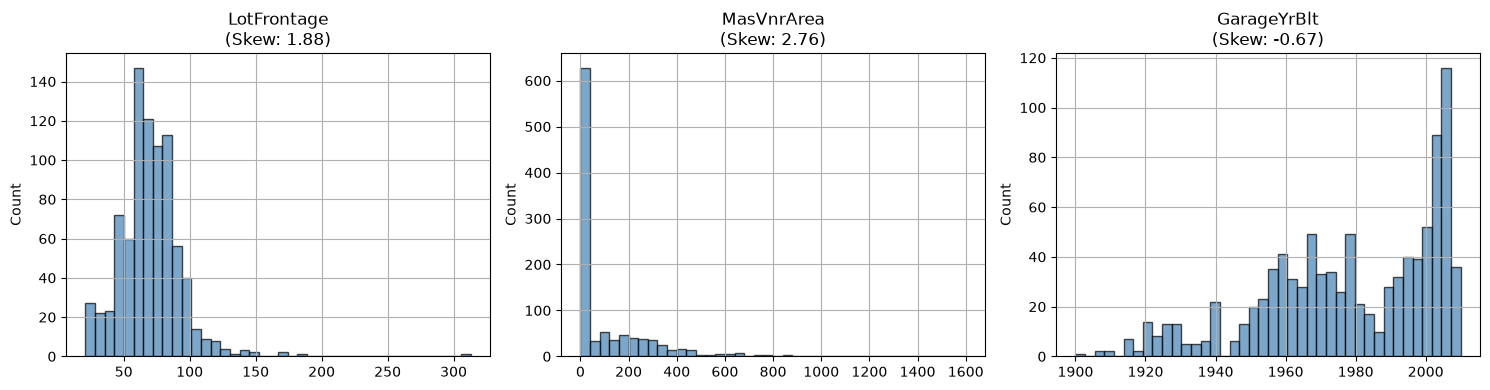

In [5]:
# Plot distributions of the features with missing values in X_train
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, col in zip(axes, vars_to_impute):
    X_train[col].hist(bins=40, ax=ax, edgecolor='black', alpha=0.7, color='steelblue')
    ax.set_title(f"{col}\n(Skew: {X_train[col].skew():.2f})")
    ax.set_ylabel("Count")

plt.tight_layout()
plt.show()

### Distribution Observations:
- **`LotFrontage`**: Moderately right-skewed.
- **`MasVnrArea`**: Highly skewed with a massive spike at 0 (most properties have no masonry veneer).
- **`GarageYrBlt`**: Left-skewed (most garages built in recent decades).

Because these features exhibit skewness, **median imputation** is preferred over mean imputation.

---
## 4. Method 1: Imputation Using Pandas

We compute the median (or mean) strictly on `X_train`, convert the values to a dictionary, and use `.fillna()` on both `X_train` and `X_test`.

In [6]:
# Calculate median values on training set ONLY
median_values = X_train[vars_to_impute].median().to_dict()
print("Computed Median Values from X_train:")
for col, val in median_values.items():
    print(f"  {col}: {val}")

Computed Median Values from X_train:
  LotFrontage: 69.0
  MasVnrArea: 0.0
  GarageYrBlt: 1979.0


In [7]:
# Create explicit copies to avoid modifying original split
X_train_pd = X_train.copy()
X_test_pd = X_test.copy()

# Impute missing values using the dictionary learned from X_train
X_train_pd.fillna(median_values, inplace=True)
X_test_pd.fillna(median_values, inplace=True)

# Verify that missing values have been eliminated
print(f"Remaining nulls in X_train: {X_train_pd[vars_to_impute].isnull().sum().sum()}")
print(f"Remaining nulls in X_test:  {X_test_pd[vars_to_impute].isnull().sum().sum()}")

Remaining nulls in X_train: 0
Remaining nulls in X_test:  0


---
## 5. Method 2: Imputation Using Scikit-Learn `SimpleImputer`

In production machine learning workflows, scikit-learn's `SimpleImputer` is preferred because it can be seamlessly embedded inside a `Pipeline`.

We configure `set_output(transform="pandas")` so the transformer outputs a clean pandas DataFrame with column names preserved.

In [8]:
# Initialize SimpleImputer with median strategy
imputer = SimpleImputer(strategy='median')
imputer.set_output(transform="pandas")

# Fit the imputer on X_train (learns medians)
imputer.fit(X_train)

# Inspect the learned statistics
print("SimpleImputer learned statistics:")
for col, stat in zip(X_train.columns, imputer.statistics_):
    print(f"  {col:15s}: {stat}")

SimpleImputer learned statistics:
  LotFrontage    : 69.0
  OverallQual    : 6.0
  MasVnrArea     : 0.0
  TotalBsmtSF    : 992.0
  1stFlrSF       : 1095.0
  GrLivArea      : 1479.0
  GarageYrBlt    : 1979.0


In [9]:
# Transform both train and test sets
X_train_sk = imputer.transform(X_train)
X_test_sk = imputer.transform(X_test)

# Verify that outputs are clean DataFrames with 0 nulls
print(f"X_train_sk nulls: {X_train_sk.isnull().sum().sum()}")
print(f"X_test_sk nulls:  {X_test_sk.isnull().sum().sum()}")
X_train_sk[vars_to_impute].head()

X_train_sk nulls: 0
X_test_sk nulls:  0


,LotFrontage,MasVnrArea,GarageYrBlt
64,69.0,573.0,1998.0
682,69.0,0.0,1996.0
960,50.0,0.0,1979.0
1384,60.0,0.0,1939.0
1100,60.0,0.0,1930.0


---
## 6. Evaluating the Impact of Imputation

Let's examine how median imputation altered the distribution and variance of `LotFrontage`.

In [10]:
# Compare variance before and after imputation on X_train
for col in vars_to_impute:
    var_before = X_train[col].var()
    var_after = X_train_sk[col].var()
    change = ((var_after - var_before) / var_before) * 100
    print(f"{col:15s} | Var Before: {var_before:10.2f} | Var After: {var_after:10.2f} | Change: {change:+.2f}%")

LotFrontage     | Var Before:     532.59 | Var After:     434.07 | Change: -18.50%
MasVnrArea      | Var Before:   32983.54 | Var After:   32874.27 | Change: -0.33%
GarageYrBlt     | Var Before:     624.31 | Var After:     591.34 | Change: -5.28%


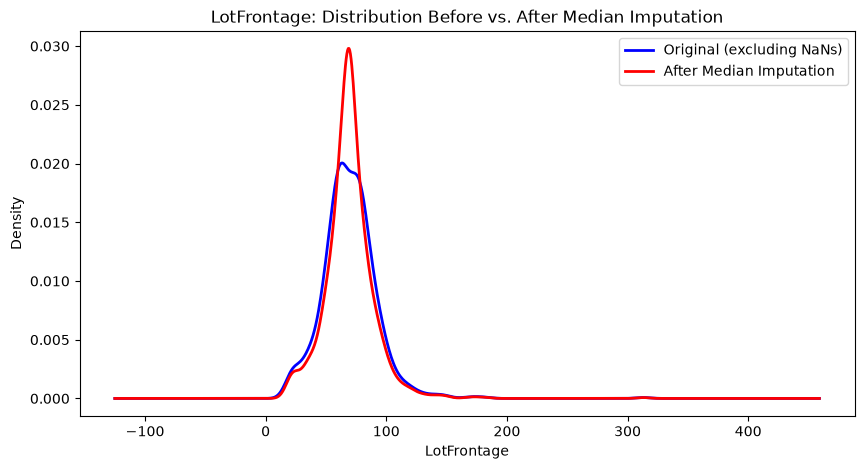

In [11]:
# Visual comparison of distribution before and after imputation
fig, ax = plt.subplots(figsize=(10, 5))

# Original distribution (excluding NaNs for plot)
X_train['LotFrontage'].plot(kind='kde', ax=ax, color='blue', label='Original (excluding NaNs)', lw=2)

# After Median Imputation
X_train_sk['LotFrontage'].plot(kind='kde', ax=ax, color='red', label='After Median Imputation', lw=2)

ax.set_title('LotFrontage: Distribution Before vs. After Median Imputation')
ax.set_xlabel('LotFrontage')
ax.legend()
plt.show()

### Key Observations:
1. **Variance Reduction**: Notice how the variance of `LotFrontage` decreased by ~18%. Because we replaced ~18% of the rows with a constant (the median $69.0$), that constant adds $0$ variance to the feature.
2. **Probability Mass Spike**: The KDE plot shows a sharp peak around $69.0$. While the overall range is preserved, the natural spread of the data is compressed.

---
## 7. Summary & Best Practices Checklist

| Consideration | Recommendation |
| :--- | :--- |
| **Normal vs. Skewed** | Use **mean** for symmetric/Gaussian data; use **median** for skewed data or when outliers exist. |
| **Data Leakage** | Always fit the imputer on `X_train` only; apply fitted parameters to `X_test`. |
| **Missing Percentage** | Best for features with $< 5\%$ missingness. When missingness is high ($> 10\%$), consider adding a **Missing Indicator** (see notebook 05). |
| **Pipeline Integration** | Use scikit-learn's `SimpleImputer` inside a `Pipeline` or `ColumnTransformer` to ensure automated, leakage-free inference. |
